<div align="center">

# COMSATS UNIVERSITY ISLAMABAD
### Department of Computer Science / Artificial Intelligence

## ARTIFICIAL NEURAL NETWORKS
### LAB 04  |  Self Organizing Map (SOM)

</div>

| **Student Information** | **Details** |
|:---|:---|
| **Name** | Ayesha Mehmood |
| **Registration No.** | FA23-BAI-010 |
| **Instructor** | Sir Zaeem Akbar Khan |
| **University** | COMSATS University Islamabad |
| **Lab Number** | Lab 04 |

---

**Instructions:** Run the code cells from top to bottom. The nine task sections follow the supplied ANN lab sheet. All saved outputs were generated by executing the code. Example values are demonstration data, not personal academic records.

**Requirements:** Python 3, NumPy, and matplotlib. If needed, run %pip install numpy matplotlib in a new code cell. Task 6 saves task6_result.png in the current working directory.

## Lab Tasks


---
## Task 1: Data and Weight Setup

Write code to generate 200 random colors (each with R, G, B values between 0 and 1) using NumPy.

Write code to create a 10 x 10 grid of neurons, where each neuron has a random weight vector of 3 values.

Display the initial weight grid as an image using plt.imshow().

Write code to print the shape, minimum value and maximum value of both the data and the weight grid.


Data shape: (200, 3) Minimum: 0.0054298341287004614 Maximum: 0.9991047304742386
Weight shape: (10, 10, 3) Minimum: 0.001233062511908134 Maximum: 0.9987433700667648


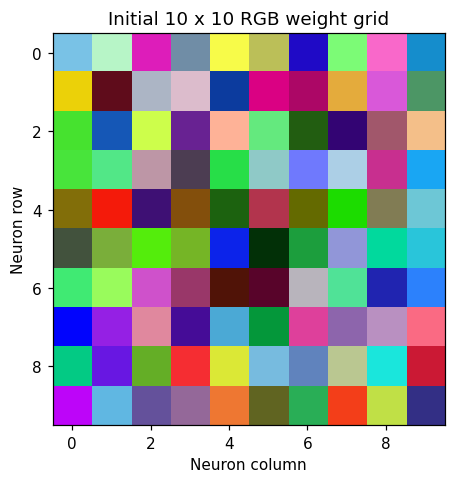

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 110})
rng = np.random.default_rng(42)
data = rng.random((200, 3))
initial_weights = rng.random((10, 10, 3))
print("Data shape:", data.shape, "Minimum:", data.min(), "Maximum:", data.max())
print("Weight shape:", initial_weights.shape, "Minimum:", initial_weights.min(), "Maximum:", initial_weights.max())
plt.imshow(initial_weights)
plt.title("Initial 10 x 10 RGB weight grid")
plt.xlabel("Neuron column")
plt.ylabel("Neuron row")
plt.tight_layout()
plt.show()


---
## Task 2: Distance Calculation

Write a function euclidean_distance(a, b) that returns the distance between two vectors.

Pick one random sample from the data and compute its distance to every neuron in the grid using vectorized NumPy code (no nested loops). The result must be a 10 x 10 array.

Display the distance array as a heatmap with a colorbar.

Write code to print the smallest distance and the row and column where it occurs.


Selected sample: 11 [0.3705 0.4696 0.1895]
Distance array shape: (10, 10)
Minimum distance: 0.09562551328127235 Row: 9 Column: 5
Function check: 0.09562551328127235


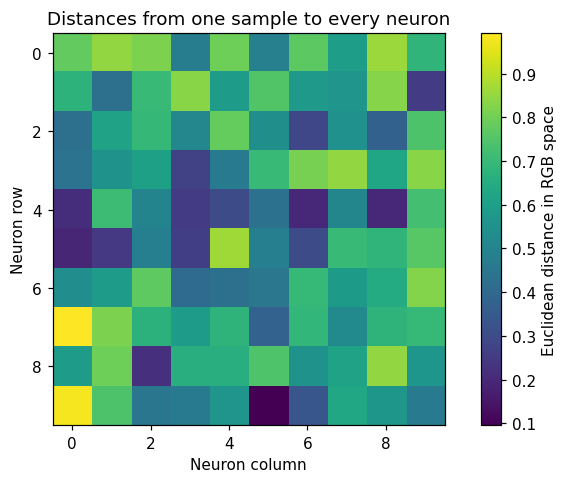

In [2]:
def euclidean_distance(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)))

sample_index = int(rng.integers(len(data)))
sample = data[sample_index]
distances = np.linalg.norm(initial_weights - sample, axis=2)
position = np.unravel_index(np.argmin(distances), distances.shape)
print("Selected sample:", sample_index, sample)
print("Distance array shape:", distances.shape)
print("Minimum distance:", distances[position], "Row:", position[0], "Column:", position[1])
print("Function check:", euclidean_distance(initial_weights[position], sample))
plt.imshow(distances, cmap="viridis")
plt.colorbar(label="Euclidean distance in RGB space")
plt.title("Distances from one sample to every neuron")
plt.xlabel("Neuron column")
plt.ylabel("Neuron row")
plt.tight_layout()
plt.show()


---
## Task 3: Finding the Winner (BMU)

Write a function find_bmu(weights, x) that returns the (row, column) of the Best Matching Unit.

Call the function on 5 different samples and print the results in a neat format: sample number, BMU position, distance.

Display the weight grid and mark the BMU of one sample with a red marker using plt.scatter().

Find the BMU of all 200 samples, count how many samples land on each neuron, and display the counts as a 10 x 10 heatmap (a hit map).


Sample   BMU position     Distance
     1         (1, 8)     0.120392
     2         (9, 0)     0.084833
     3         (9, 8)     0.177702
     4         (3, 6)     0.126020
     5         (0, 5)     0.150898
Total hits: 200


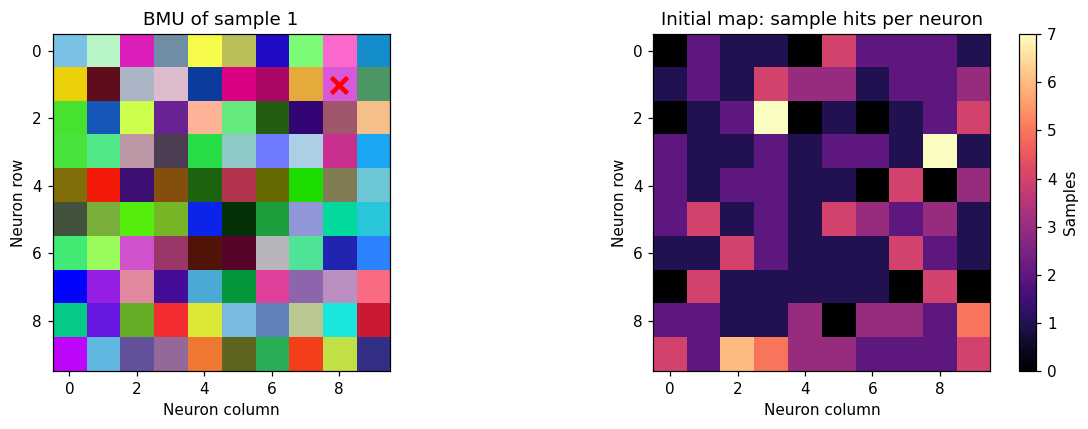

In [3]:
def find_bmu(weights, x):
    distances = np.linalg.norm(weights - x, axis=2)
    row, column = np.unravel_index(np.argmin(distances), distances.shape)
    return int(row), int(column)

print(f"{'Sample':>6} {'BMU position':>14} {'Distance':>12}")
for index in range(5):
    bmu = find_bmu(initial_weights, data[index])
    print(f"{index + 1:>6} {str(bmu):>14} {euclidean_distance(initial_weights[bmu], data[index]):>12.6f}")
selected_bmu = find_bmu(initial_weights, data[0])
hit_counts = np.zeros(initial_weights.shape[:2], dtype=int)
for x in data:
    hit_counts[find_bmu(initial_weights, x)] += 1
print("Total hits:", hit_counts.sum())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(initial_weights)
axes[0].scatter(selected_bmu[1], selected_bmu[0], c="red", s=110, marker="x", linewidths=3)
axes[0].set_title("BMU of sample 1")
image = axes[1].imshow(hit_counts, cmap="magma")
axes[1].set_title("Initial map: sample hits per neuron")
fig.colorbar(image, ax=axes[1], label="Samples")
for ax in axes:
    ax.set(xlabel="Neuron column", ylabel="Neuron row")
plt.tight_layout()
plt.show()


---
## Task 4: Neighborhood Function

Write a function neighborhood(grid_size, bmu, radius) that returns a 2D array of Gaussian values h, equal to 1 at the BMU and smaller farther away.

Plot the output for a BMU at (5, 5) with radius 1, 3 and 5 in three side-by-side subplots.

Write a second version of the function that sets h to 0 for every neuron farther than the radius (a bubble neighborhood), and plot it next to the Gaussian version.

Write code to print the value of h at the BMU and at a neuron 3 steps away, using radius 2.


The Gaussian uses grid distance, not RGB distance: $h=\exp(-d_{grid}^2/(2r^2))$. A bubble neighborhood is 1 inside the radius and 0 outside. Unlike the bubble, the Gaussian has a nonzero tail beyond the radius.


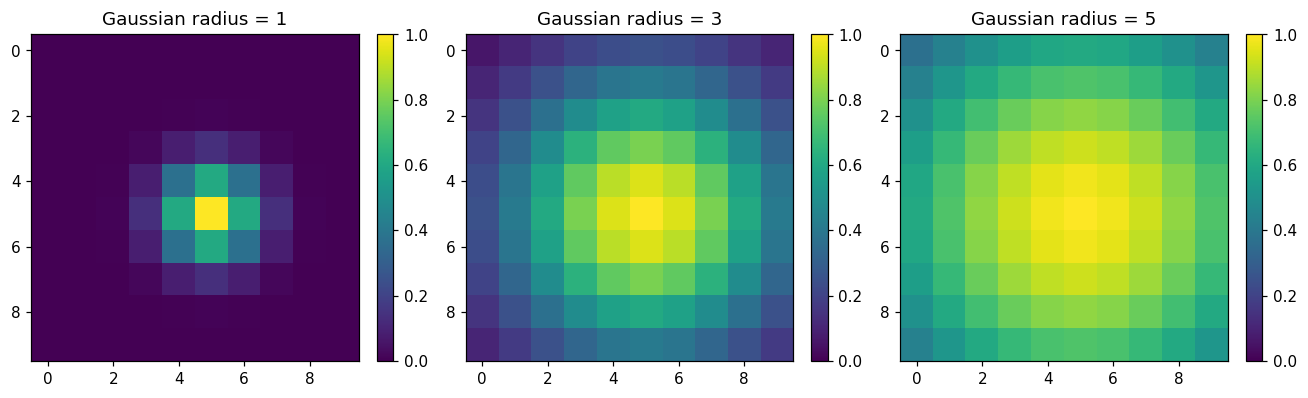

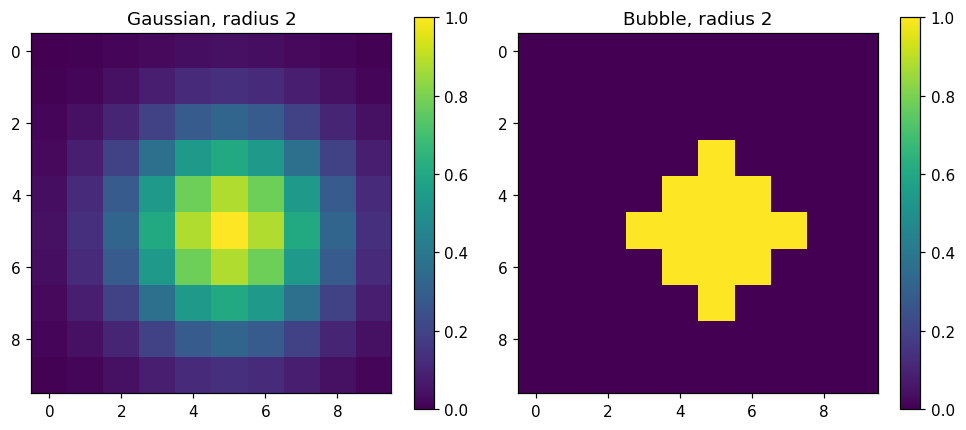

Gaussian: BMU value = 1.0 ; three steps away = 0.32465246735834974
Bubble: BMU value = 1.0 ; three steps away = 0.0


In [4]:
def neighborhood(grid_size, bmu, radius):
    if radius <= 0:
        raise ValueError("Radius must be positive")
    rows, cols = np.indices((grid_size, grid_size))
    distance_squared = (rows - bmu[0])**2 + (cols - bmu[1])**2
    return np.exp(-distance_squared / (2 * radius**2))

def bubble_neighborhood(grid_size, bmu, radius):
    rows, cols = np.indices((grid_size, grid_size))
    distance_squared = (rows - bmu[0])**2 + (cols - bmu[1])**2
    # A bubble gives equal influence inside the radius and zero outside.
    return (distance_squared <= radius**2).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, radius in zip(axes, [1, 3, 5]):
    image = ax.imshow(neighborhood(10, (5, 5), radius), vmin=0, vmax=1, cmap="viridis")
    ax.set_title(f"Gaussian radius = {radius}")
    fig.colorbar(image, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
gaussian_h = neighborhood(10, (5, 5), 2)
bubble_h = bubble_neighborhood(10, (5, 5), 2)
for ax, h, title in zip(axes, [gaussian_h, bubble_h], ["Gaussian, radius 2", "Bubble, radius 2"]):
    image = ax.imshow(h, vmin=0, vmax=1, cmap="viridis")
    ax.set_title(title)
    fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()
print("Gaussian: BMU value =", gaussian_h[5, 5], "; three steps away =", gaussian_h[5, 8])
print("Bubble: BMU value =", bubble_h[5, 5], "; three steps away =", bubble_h[5, 8])


---
## Task 5: One Weight Update Step

Write a function update_weights(weights, x, bmu, learning_rate, radius) that applies one SOM update and returns the new weights.

Apply the function once and show the weight grid before and after in two subplots.

Write code to compute and print the total absolute change in the weights caused by this single update.

Write code to print the distance between the BMU and the sample before and after the update, and confirm with an if statement that it decreased.


Total absolute weight change: 6.730546734259151
BMU distance before: 0.12039173728949479
BMU distance after: 0.06019586864474736
Confirmed: the BMU moved closer to the sample.


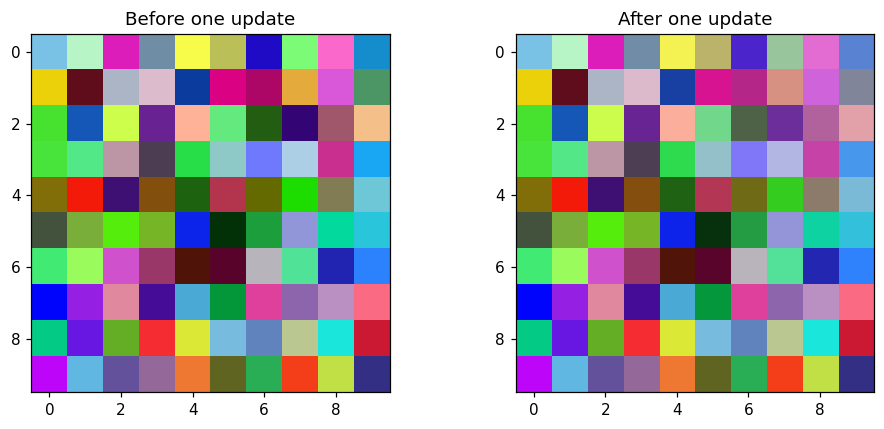

In [5]:
def update_weights(weights, x, bmu, learning_rate, radius):
    influence = neighborhood(weights.shape[0], bmu, radius)
    # Broadcasting applies one update to all neurons and RGB components.
    return weights + learning_rate * influence[..., None] * (x - weights)

x = data[0]
bmu = find_bmu(initial_weights, x)
updated_weights = update_weights(initial_weights, x, bmu, learning_rate=0.5, radius=2.0)
before = euclidean_distance(initial_weights[bmu], x)
after = euclidean_distance(updated_weights[bmu], x)
print("Total absolute weight change:", np.abs(updated_weights - initial_weights).sum())
print("BMU distance before:", before)
print("BMU distance after:", after)
if after < before:
    print("Confirmed: the BMU moved closer to the sample.")
else:
    print("Distance did not decrease; inspect the sample and parameters.")
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(initial_weights)
axes[0].set_title("Before one update")
axes[1].imshow(updated_weights)
axes[1].set_title("After one update")
plt.tight_layout()
plt.show()


---
## Task 6: Training Loop

Write a function train_som(data, grid_size, iterations, lr_start, radius_start) that runs the full training and returns the trained weights. The learning rate and radius must shrink with every iteration using exponential decay.

Inside the loop, store the learning rate and radius every 100 iterations in two lists.

Plot both lists on one line graph with a legend.

Show the initial and trained weight grids side by side, and save the figure as task6_result.png.


The update is $w_i\leftarrow w_i+\alpha h_i(x-w_i)$. Both schedules decay at every update: $\alpha(t)=\alpha_0 e^{-t/\tau_\alpha}$ and $r(t)=r_0 e^{-t/\tau_r}$, with $\tau_\alpha=T/\ln(10)$ and $\tau_r=T/\ln(10)$ for iteration budget $T$. Thus the final learning rate and radius are approximately one tenth of their starting values. Each iteration draws one sample; it is not a full pass through the dataset. Quantization error recording is included here and used in Task 7.


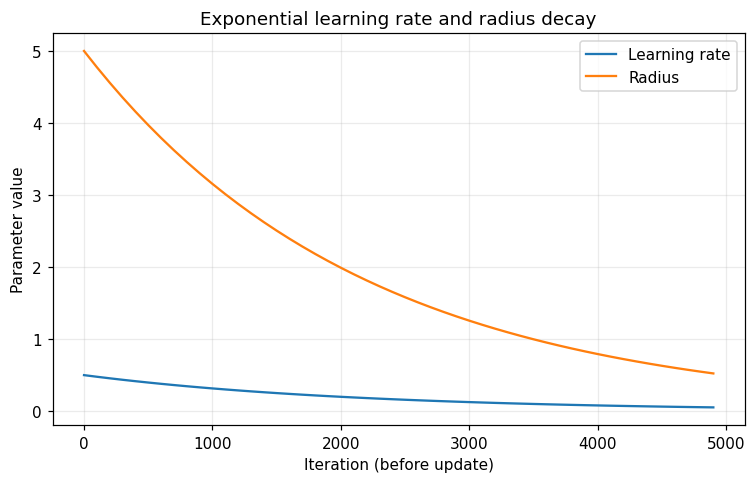

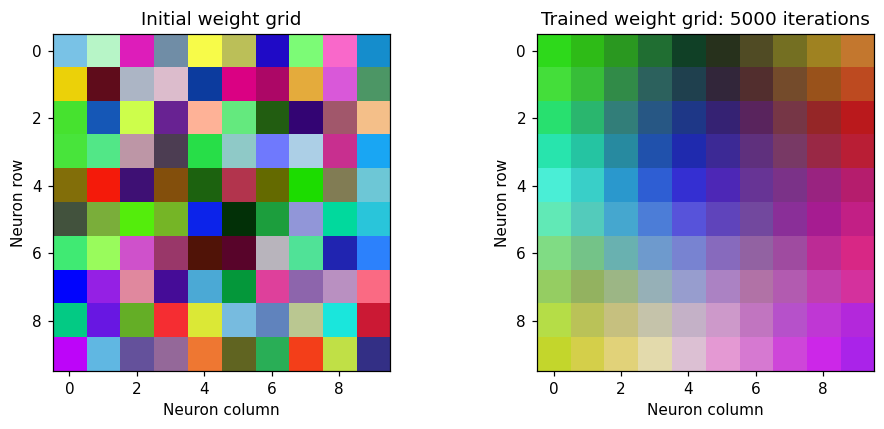

Saved figure: task6_result.png
Recorded learning rate entries: 50
Recorded radius entries: 50


In [6]:
def quantization_error(data, weights):
    # One BMU distance per sample; mean distance, not mean squared distance.
    distances = np.linalg.norm(data[:, None, None, :] - weights[None, :, :, :], axis=-1)
    return float(distances.min(axis=(1, 2)).mean())

def train_som(data, grid_size, iterations, lr_start, radius_start,
              seed=42, initial=None, return_history=False):
    if iterations < 1 or grid_size < 1 or not 0 < lr_start <= 1 or radius_start <= 0:
        raise ValueError("Use positive sizes/radius and 0 < learning rate <= 1")
    # Separate generators keep sampled input order independent of grid size.
    weight_rng = np.random.default_rng(seed)
    sample_rng = np.random.default_rng(seed + 1)
    weights = (weight_rng.random((grid_size, grid_size, data.shape[1]))
               if initial is None else np.array(initial, dtype=float, copy=True))
    if weights.shape != (grid_size, grid_size, data.shape[1]):
        raise ValueError("Initial weight grid has the wrong shape")
    history = {"schedule_steps": [], "learning_rates": [], "radii": [],
               "error_steps": [0], "errors": [quantization_error(data, weights)],
               "initial_weights": weights.copy()}
    lr_decay_time = float(iterations) / np.log(10.0)
    radius_decay_time = float(iterations) / np.log(10.0)
    for step in range(iterations):
        learning_rate = lr_start * np.exp(-step / lr_decay_time)
        radius = radius_start * np.exp(-step / radius_decay_time)
        x = data[int(sample_rng.integers(len(data)))]
        bmu = find_bmu(weights, x)
        weights = update_weights(weights, x, bmu, learning_rate, radius)
        if step % 100 == 0:
            history["schedule_steps"].append(step)
            history["learning_rates"].append(float(learning_rate))
            history["radii"].append(float(radius))
        if (step + 1) % 250 == 0 or step + 1 == iterations:
            history["error_steps"].append(step + 1)
            history["errors"].append(quantization_error(data, weights))
    return (weights, history) if return_history else weights

trained_weights, training_history = train_som(data, grid_size=10, iterations=5000,
    lr_start=0.5, radius_start=5.0, initial=initial_weights, return_history=True)
# Default return is just trained weights; optional history supports Tasks 6 and 7.
plt.figure()
plt.plot(training_history["schedule_steps"], training_history["learning_rates"], label="Learning rate")
plt.plot(training_history["schedule_steps"], training_history["radii"], label="Radius")
plt.xlabel("Iteration (before update)")
plt.ylabel("Parameter value")
plt.title("Exponential learning rate and radius decay")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(training_history["initial_weights"])
axes[0].set_title("Initial weight grid")
axes[1].imshow(trained_weights)
axes[1].set_title("Trained weight grid: 5000 iterations")
for ax in axes:
    ax.set(xlabel="Neuron column", ylabel="Neuron row")
plt.tight_layout()
fig.savefig("task6_result.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved figure: task6_result.png")
print("Recorded learning rate entries:", len(training_history["learning_rates"]))
print("Recorded radius entries:", len(training_history["radii"]))


---
## Task 7: Measuring Training Quality

Write a function quantization_error(data, weights) that returns the average distance between each sample and its own BMU weight vector.

Modify your training function to record the quantization error every 250 iterations.

Plot the error against the iteration number as a line graph with axis labels and a title.

Write code to print the first error, the last error and the percentage reduction between them.


Quantization error measures how closely weights represent observed colors. It does not measure topology preservation, and individual training updates need not reduce the average error monotonically.


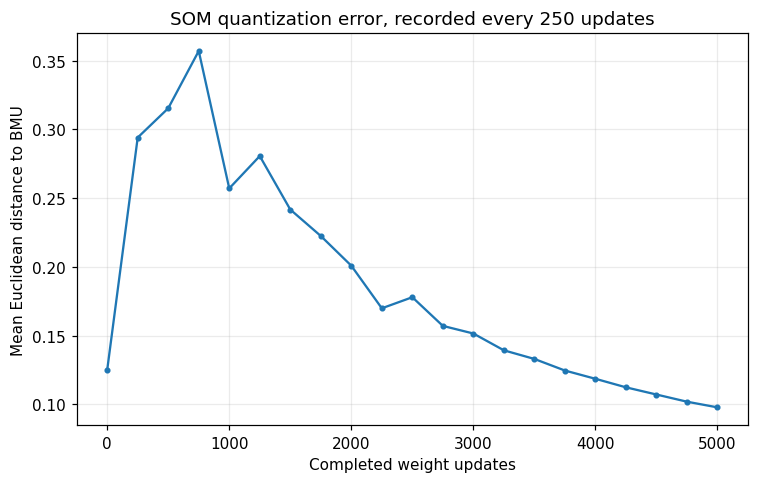

First error (before training): 0.12491458073200759
Last error: 0.0977351025242832
Percentage reduction: 21.76%
A negative reduction means error increased; it must not be relabeled as an improvement.


In [7]:
first_error = training_history["errors"][0]
last_error = training_history["errors"][-1]
percentage_reduction = 100 * (first_error - last_error) / first_error if first_error else 0.0
plt.figure()
plt.plot(training_history["error_steps"], training_history["errors"], marker="o", markersize=3)
plt.xlabel("Completed weight updates")
plt.ylabel("Mean Euclidean distance to BMU")
plt.title("SOM quantization error, recorded every 250 updates")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("First error (before training):", first_error)
print("Last error:", last_error)
print("Percentage reduction:", f"{percentage_reduction:.2f}%")
print("A negative reduction means error increased; it must not be relabeled as an improvement.")


---
## Task 8: Parameter Experiments

Write a loop that trains the SOM with iterations of 10, 500 and 5000, and show the three resulting maps side by side with titles.

Write a loop that trains with grid sizes of 5, 10 and 20, and show the three maps side by side.

Write a loop that trains with learning rates of 0.01, 0.5 and 0.9, and show the three maps side by side.

Collect the quantization error of every experiment above and print one summary table (setting name, value, final error) using a loop.


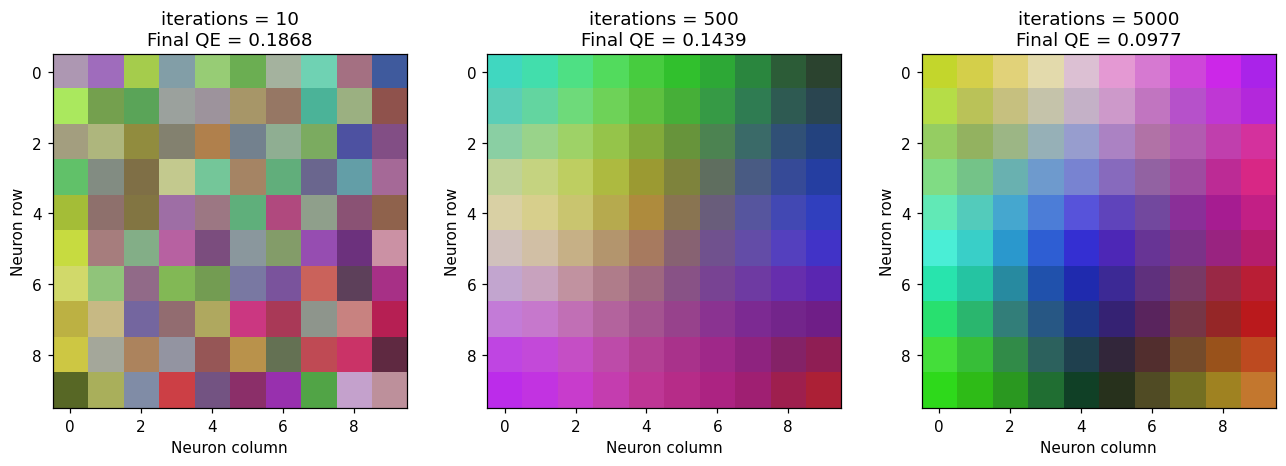

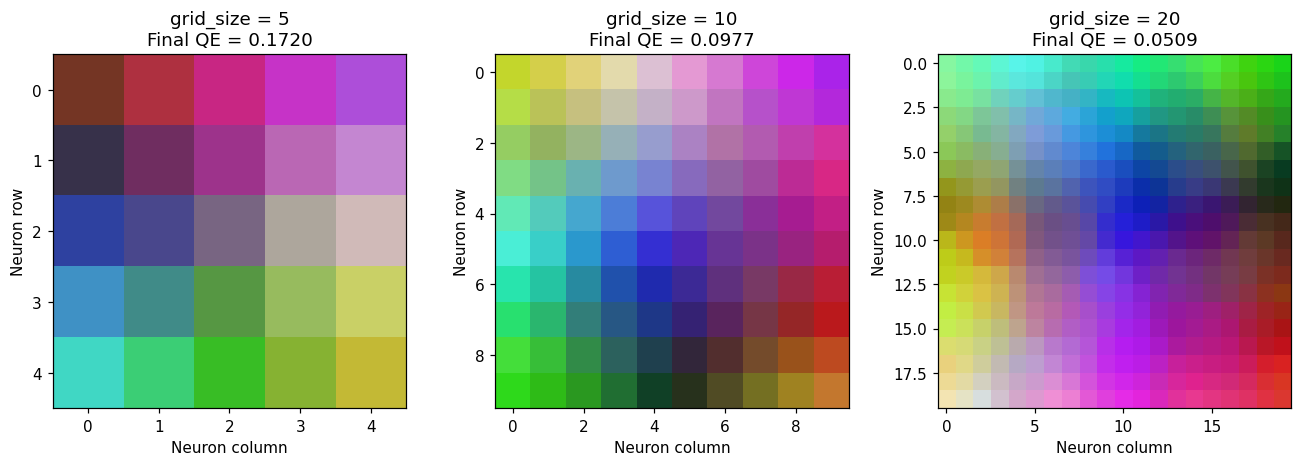

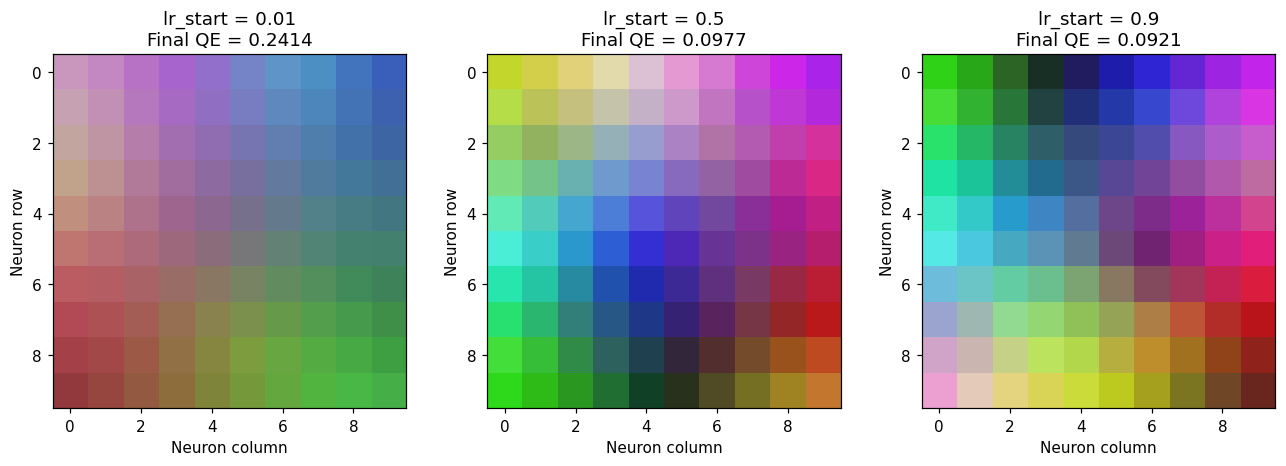

Setting                 Value     Final error
iterations                 10        0.186792
iterations                500        0.143947
iterations               5000        0.097735
grid_size                   5        0.172037
grid_size                  10        0.097735
grid_size                  20        0.050916
lr_start                 0.01        0.241414
lr_start                  0.5        0.097735
lr_start                  0.9        0.092103
More neurons can reduce quantization error by increasing capacity; that alone does not prove better topology.
Both decay time constants scale with the iteration budget, so different budgets share the same normalized schedule.
These are single-seed training-data comparisons, not a universal parameter ranking.


In [8]:
experiment_rows = []
# Within each family, change one parameter. Use seed 42 throughout.
def run_experiment_family(setting, values):
    fig, axes = plt.subplots(1, len(values), figsize=(12, 4))
    for ax, value in zip(axes, values):
        parameters = dict(grid_size=10, iterations=5000, lr_start=0.5, radius_start=5.0, seed=42)
        parameters[setting] = value
        # Radius stays fixed at 5 in the grid-size experiment, so only grid size changes.
        result = train_som(data, **parameters)
        error = quantization_error(data, result)
        experiment_rows.append((setting, value, error))
        ax.imshow(result)
        ax.set_title(f"{setting} = {value}\nFinal QE = {error:.4f}")
        ax.set(xlabel="Neuron column", ylabel="Neuron row")
    plt.tight_layout()
    plt.show()

run_experiment_family("iterations", [10, 500, 5000])
run_experiment_family("grid_size", [5, 10, 20])
run_experiment_family("lr_start", [0.01, 0.5, 0.9])
print(f"{'Setting':<18} {'Value':>10} {'Final error':>15}")
print("=" * 46)
for setting, value, error in experiment_rows:
    print(f"{setting:<18} {value:>10} {error:>15.6f}")
print("More neurons can reduce quantization error by increasing capacity; that alone does not prove better topology.")
print("Both decay time constants scale with the iteration budget, so different budgets share the same normalized schedule.")
print("These are single-seed training-data comparisons, not a universal parameter ranking.")


---
## Task 9: Mini Project with Your Own Data

Write code to generate 100 samples that are close to only three base colors (red, green, blue) by adding small random noise to each, so that every value stays between 0 and 1.

Train a 10 x 10 SOM on this data and display the trained map.

Write code to find the BMU of every sample and group the samples by BMU position using a dictionary.

Print the number of neurons that received at least one sample, and plot the hit map to show how many separate groups appear.


Own data shape: (100, 3) Range: 0.0 1.0
Samples around red, green and blue: [34 33 33]
Neurons receiving at least one sample: 54
Total assigned samples: 100
Final quantization error: 0.01246759428048497
BMU groups (sample indices are zero based):
(0, 0) count = 1 sample indices = [25]
(0, 1) count = 1 sample indices = [18]
(0, 4) count = 6 sample indices = [2, 20, 39, 53, 59, 88]
(0, 5) count = 3 sample indices = [14, 66, 96]
(0, 6) count = 1 sample indices = [68]
(0, 7) count = 3 sample indices = [24, 48, 73]
(0, 8) count = 2 sample indices = [49, 52]
(1, 0) count = 1 sample indices = [62]
(1, 3) count = 4 sample indices = [4, 12, 51, 75]
(1, 5) count = 1 sample indices = [74]
(1, 6) count = 1 sample indices = [91]
(1, 9) count = 2 sample indices = [89, 92]
(2, 0) count = 1 sample indices = [31]
(2, 1) count = 1 sample indices = [8]
(2, 2) count = 1 sample indices = [11]
(2, 3) count = 1 sample indices = [55]
(2, 5) count = 2 sample indices = [60, 69]
(3, 5) count = 1 sample indices =

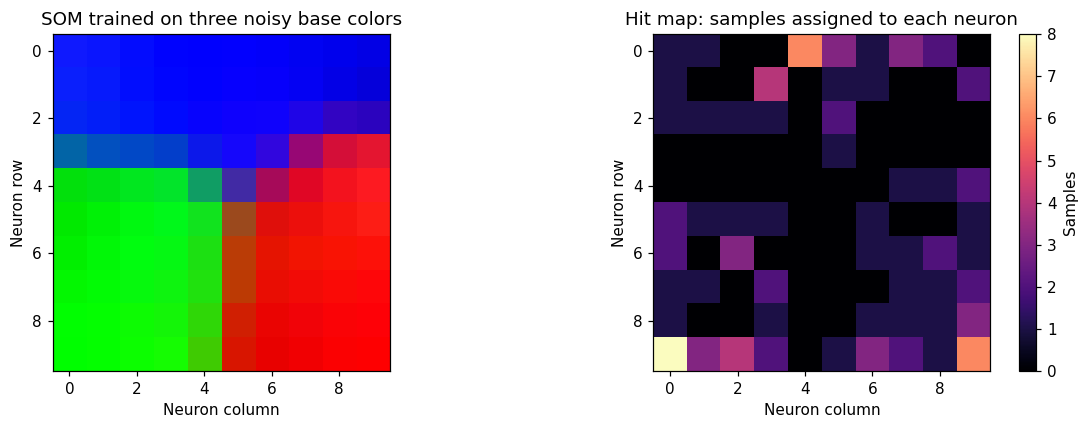

Separate occupied regions (four-neighbor adjacency): 5
Occupied neurons, connected hit regions and the three known base-color groups are different counts.
The map may use several neurons for one color group; the hit map need not contain exactly three occupied cells.


In [9]:
color_rng = np.random.default_rng(2026)
base_colors = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
base_labels = np.repeat(np.arange(3), [34, 33, 33])
color_rng.shuffle(base_labels)
own_data = np.clip(base_colors[base_labels] + color_rng.normal(0, 0.06, size=(100, 3)), 0, 1)
print("Own data shape:", own_data.shape, "Range:", own_data.min(), own_data.max())
print("Samples around red, green and blue:", np.bincount(base_labels))
own_weights = train_som(own_data, grid_size=10, iterations=5000,
                         lr_start=0.5, radius_start=5.0, seed=42)
grouped_samples = {}
own_hits = np.zeros((10, 10), dtype=int)
for index, x in enumerate(own_data):
    position = find_bmu(own_weights, x)
    grouped_samples.setdefault(position, []).append(index)
    own_hits[position] += 1
print("Neurons receiving at least one sample:", len(grouped_samples))
print("Total assigned samples:", sum(len(indices) for indices in grouped_samples.values()))
print("Final quantization error:", quantization_error(own_data, own_weights))
print("BMU groups (sample indices are zero based):")
for position, indices in sorted(grouped_samples.items()):
    print(position, "count =", len(indices), "sample indices =", indices)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(own_weights)
axes[0].set_title("SOM trained on three noisy base colors")
image = axes[1].imshow(own_hits, cmap="magma")
axes[1].set_title("Hit map: samples assigned to each neuron")
fig.colorbar(image, ax=axes[1], label="Samples")
for ax in axes:
    ax.set(xlabel="Neuron column", ylabel="Neuron row")
plt.tight_layout()
plt.show()

# Count connected occupied regions using four-neighbor grid adjacency.
unseen = set(grouped_samples)
connected_regions = 0
while unseen:
    connected_regions += 1
    stack = [unseen.pop()]
    while stack:
        row, col = stack.pop()
        for adjacent in [(row-1, col), (row+1, col), (row, col-1), (row, col+1)]:
            if adjacent in unseen:
                unseen.remove(adjacent)
                stack.append(adjacent)
print("Separate occupied regions (four-neighbor adjacency):", connected_regions)
print("Occupied neurons, connected hit regions and the three known base-color groups are different counts.")
print("The map may use several neurons for one color group; the hit map need not contain exactly three occupied cells.")
